In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from ucimlrepo import fetch_ucirepo

SEED = 42
hd = fetch_ucirepo(id=45)               # Heart Disease (Cleveland Clinic, USA)
X = hd.data.features.copy()
y = (hd.data.targets["num"] > 0).astype(int)   # 1 = heart disease

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
bin_cols = ["sex", "fbs", "exang"]
cat_cols = ["cp", "restecg", "slope", "thal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train.assign(target=y_train).to_csv("train.csv", index=False)
X_test.assign(target=y_test).to_csv("test.csv", index=False)

print(X.shape, X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts())
print(X_train.isna().sum())


(303, 13) (242, 13) (61, 13)
num
0    0.541
1    0.459
Name: proportion, dtype: float64
num
0    33
1    28
Name: count, dtype: int64
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          1
thal        1
dtype: int64


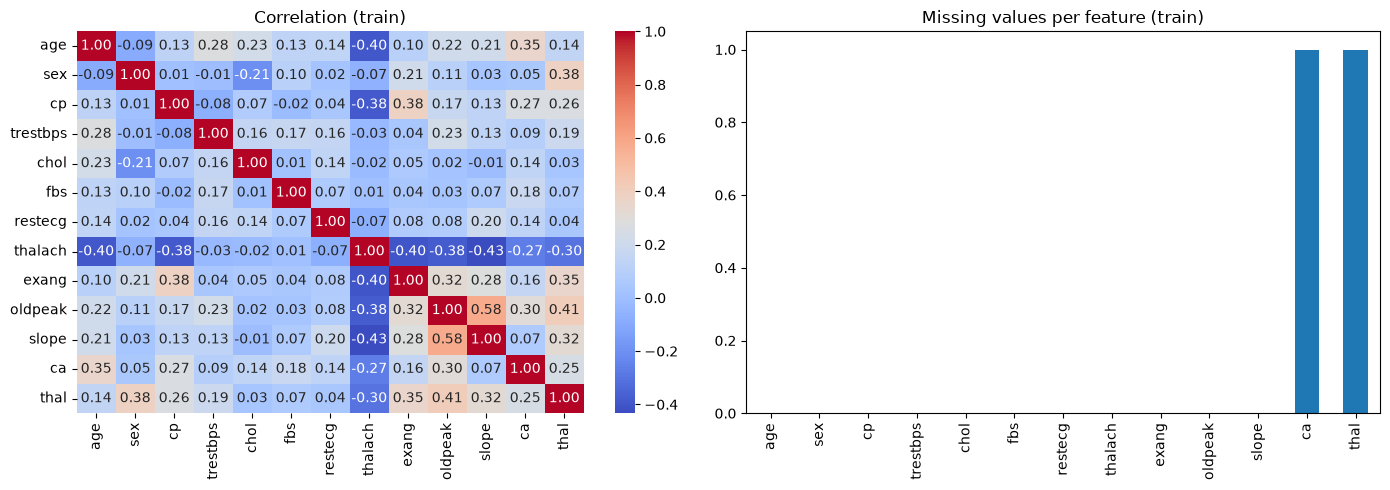

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[0])
ax[0].set_title("Correlation (train)")
X_train.isna().sum().plot.bar(ax=ax[1])
ax[1].set_title("Missing values per feature (train)")
plt.tight_layout(); plt.savefig("eda.png", dpi=300); plt.show()

In [3]:
from scipy.stats import mannwhitneyu, chi2_contingency
n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
fp = lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"
rows = []
for c in num_cols:
    a = X_train.loc[y_train == 0, c].dropna(); b = X_train.loc[y_train == 1, c].dropna()
    f = lambda s: f"{s.median():.1f} ({s.quantile(.25):.1f}-{s.quantile(.75):.1f})"
    rows.append([c, f(a), f(b), f"{X_train[c].isna().mean()*100:.1f}%",
                 fp(mannwhitneyu(a, b).pvalue)])
for c in bin_cols + cat_cols:
    ct = pd.crosstab(X_train[c], y_train)
    p = chi2_contingency(ct)[1]
    for i, lvl in enumerate(ct.index):
        rows.append([f"{c} = {lvl:g}",
                     f"{ct.loc[lvl,0]} ({ct.loc[lvl,0]/n0*100:.1f}%)",
                     f"{ct.loc[lvl,1]} ({ct.loc[lvl,1]/n1*100:.1f}%)",
                     f"{X_train[c].isna().mean()*100:.1f}%" if i == 0 else "",
                     fp(p) if i == 0 else ""])
table1 = pd.DataFrame(rows, columns=["Feature", f"No disease (n={n0})",
                                     f"Disease (n={n1})", "Missing", "p-value"])
table1.to_csv("table1.csv", index=False)
table1

,Feature,No disease (n=131),Disease (n=111),Missing,p-value
0,age,52.0 (45.0-59.0),58.0 (52.0-62.0),0.0%,<0.001
1,trestbps,129.0 (120.0-140.0),130.0 (120.0-145.0),0.0%,0.052
2,chol,240.0 (208.5-270.5),254.0 (224.0-283.5),0.0%,0.070
3,thalach,161.0 (148.5-172.0),142.0 (125.0-158.0),0.0%,<0.001
4,oldpeak,0.2 (0.0-1.1),1.2 (0.5-2.2),0.0%,<0.001
5,ca,0.0 (0.0-0.0),1.0 (0.0-2.0),0.4%,<0.001
6,sex = 0,59 (45.0%),18 (16.2%),0.0%,<0.001
7,sex = 1,72 (55.0%),93 (83.8%),,
8,fbs = 0,114 (87.0%),93 (83.8%),0.0%,0.596
9,fbs = 1,17 (13.0%),18 (16.2%),,


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

num_all = num_cols + bin_cols

def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_all),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore",
                                               sparse_output=False))]), cat_cols),
    ])

def pipe(clf):
    return Pipeline([("pre", make_pre()), ("clf", clf)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
lr = pipe(LogisticRegression(max_iter=1000))
scores = cross_val_score(lr, X_train, y_train, cv=cv, scoring="roc_auc")
print("Fold AUCs:", scores.round(3))
print("Mean AUC: %.3f ± %.3f" % (scores.mean(), scores.std()))

Fold AUCs: [0.915 0.934 0.893 0.913 0.878]
Mean AUC: 0.907 ± 0.019


In [5]:
import time, joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

spaces = {
 "LogReg": (LogisticRegression(max_iter=2000),
            {"clf__C": loguniform(1e-3, 1e2)}),
 "SVM":    (SVC(kernel="rbf", probability=True, random_state=SEED),
            {"clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-4, 1)}),
 "RF":     (RandomForestClassifier(random_state=SEED, n_jobs=-1),
            {"clf__n_estimators": randint(100, 400),
             "clf__max_depth": [None, 3, 5, 8],
             "clf__min_samples_leaf": randint(1, 10)}),
 "XGBoost":(XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="logloss"),
            {"clf__n_estimators": randint(100, 400),
             "clf__max_depth": randint(2, 6),
             "clf__learning_rate": loguniform(0.01, 0.3),
             "clf__subsample": uniform(0.6, 0.4)}),
 "MLP":    (MLPClassifier(max_iter=1000, random_state=SEED),
            {"clf__hidden_layer_sizes": [(16,), (32,), (32, 16)],
             "clf__alpha": loguniform(1e-5, 1e-1)}),
 "kNN":    (KNeighborsClassifier(),
            {"clf__n_neighbors": randint(3, 31),
             "clf__weights": ["uniform", "distance"]}),
}

inner = StratifiedKFold(3, shuffle=True, random_state=SEED + 1)
fold_scores, best_models, best_params, train_time = {}, {}, {}, {}

for name, (clf, grid) in spaces.items():
    t0 = time.time()
    search = RandomizedSearchCV(pipe(clf), grid, n_iter=15, cv=inner,
                                scoring="roc_auc", random_state=SEED, n_jobs=-1)
    fold_scores[name] = cross_val_score(search, X_train, y_train,
                                        cv=cv, scoring="roc_auc")
    search.fit(X_train, y_train)
    best_params[name] = search.best_params_
    m = clone(search.best_estimator_)
    t1 = time.time(); m.fit(X_train, y_train); train_time[name] = time.time() - t1
    best_models[name] = m
    print(f"{name}: AUC {fold_scores[name].mean():.3f} ± {fold_scores[name].std():.3f}"
          f"  ({time.time()-t0:.0f}s)")

pd.DataFrame(fold_scores).round(3).to_csv("fold_scores.csv", index=False)
pd.Series(best_params).to_csv("best_params.csv")
joblib.dump(best_models, "best_models.pkl")
pd.DataFrame(fold_scores).round(3)

LogReg: AUC 0.908 ± 0.022  (16s)


C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=

SVM: AUC 0.902 ± 0.021  (6s)
RF: AUC 0.902 ± 0.024  (72s)
XGBoost: AUC 0.875 ± 0.040  (96s)


C:\ml\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000

MLP: AUC 0.843 ± 0.021  (74s)
kNN: AUC 0.887 ± 0.032  (6s)


,LogReg,SVM,RF,XGBoost,MLP,kNN
0,0.921,0.911,0.950,0.933,0.871,0.913
1,0.936,0.933,0.894,0.869,0.840,0.896
2,0.892,0.876,0.888,0.809,0.844,0.864
3,0.918,0.911,0.895,0.888,0.853,0.925
4,0.874,0.879,0.885,0.876,0.808,0.837


In [6]:
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score,
                             f1_score, brier_score_loss, roc_curve, confusion_matrix)
from sklearn.model_selection import cross_val_predict
import pickle

thr = {}
for name, m in best_models.items():
    oof = cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, th = roc_curve(y_train, oof)
    thr[name] = th[np.where(tpr >= 0.80)[0][0]]

yt = y_test.values
probs = {n: m.predict_proba(X_test)[:, 1] for n, m in best_models.items()}

def metrics(y, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p),
                BalAcc=balanced_accuracy_score(y, pred), F1=f1_score(y, pred),
                Sens=tp/(tp+fn), Spec=tn/(tn+fp),
                PPV=tp/(tp+fp) if tp+fp else np.nan,
                NPV=tn/(tn+fn) if tn+fn else np.nan,
                Brier=brier_score_loss(y, p))

rng = np.random.default_rng(SEED)
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]
idx = [i for i in idx if 0 < yt[i].sum() < len(i)]
boot = {n: pd.DataFrame([metrics(yt[i], p[i], thr[n]) for i in idx])
        for n, p in probs.items()}

rows = []
for n, p in probs.items():
    pt = metrics(yt, p, thr[n])
    lo, hi = boot[n].quantile(.025), boot[n].quantile(.975)
    rows.append({"Model": n, **{k: f"{pt[k]:.3f} ({lo[k]:.3f}-{hi[k]:.3f})" for k in pt}})
results = pd.DataFrame(rows).set_index("Model")
results.to_csv("results.csv")

X1000 = pd.concat([X_test] * (1000 // len(X_test) + 1)).iloc[:1000]
eff = []
for n, m in best_models.items():
    t = time.time(); m.predict_proba(X1000); inf = time.time() - t
    eff.append([n, round(train_time[n], 3), round(inf, 4), round(len(pickle.dumps(m)) / 1e6, 3)])
eff = pd.DataFrame(eff, columns=["Model", "Train time (s)",
                                 "Inference per 1000 (s)", "Size (MB)"]).set_index("Model")
eff.to_csv("efficiency.csv")
display(results); display(eff)

C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=

,AUC,PR_AUC,BalAcc,F1,Sens,Spec,PPV,NPV,Brier
Model,,,,,,,,,
LogReg,0.963 (0.905-1.000),0.946 (0.854-1.000),0.873 (0.786-0.952),0.867 (0.769-0.952),0.929 (0.821-1.000),0.818 (0.686-0.941),0.812 (0.677-0.941),0.931 (0.821-1.000),0.089 (0.057-0.127)
SVM,0.958 (0.899-0.996),0.946 (0.856-0.995),0.858 (0.773-0.939),0.852 (0.755-0.941),0.929 (0.821-1.000),0.788 (0.639-0.923),0.788 (0.656-0.920),0.929 (0.818-1.000),0.089 (0.051-0.133)
RF,0.957 (0.898-0.995),0.946 (0.862-0.995),0.889 (0.807-0.957),0.881 (0.784-0.954),0.929 (0.821-1.000),0.848 (0.722-0.963),0.839 (0.706-0.960),0.933 (0.833-1.000),0.101 (0.072-0.134)
XGBoost,0.957 (0.899-0.995),0.943 (0.846-0.995),0.922 (0.852-0.981),0.915 (0.833-0.981),0.964 (0.880-1.000),0.879 (0.767-0.972),0.871 (0.750-0.971),0.967 (0.893-1.000),0.081 (0.041-0.129)
MLP,0.920 (0.839-0.976),0.902 (0.781-0.978),0.831 (0.742-0.914),0.831 (0.722-0.917),0.964 (0.885-1.000),0.697 (0.545-0.850),0.730 (0.588-0.865),0.958 (0.857-1.000),0.131 (0.070-0.202)
kNN,0.961 (0.907-0.996),0.952 (0.876-0.996),0.873 (0.790-0.951),0.867 (0.762-0.949),0.929 (0.821-1.000),0.818 (0.683-0.943),0.812 (0.667-0.938),0.931 (0.826-1.000),0.089 (0.062-0.123)


,Train time (s),Inference per 1000 (s),Size (MB)
Model,,,
LogReg,0.036,0.0095,0.004
SVM,0.058,0.0280,0.029
RF,0.805,0.1278,0.830
XGBoost,0.996,0.0247,0.221
MLP,1.704,0.0168,0.041
kNN,0.058,0.0195,0.048


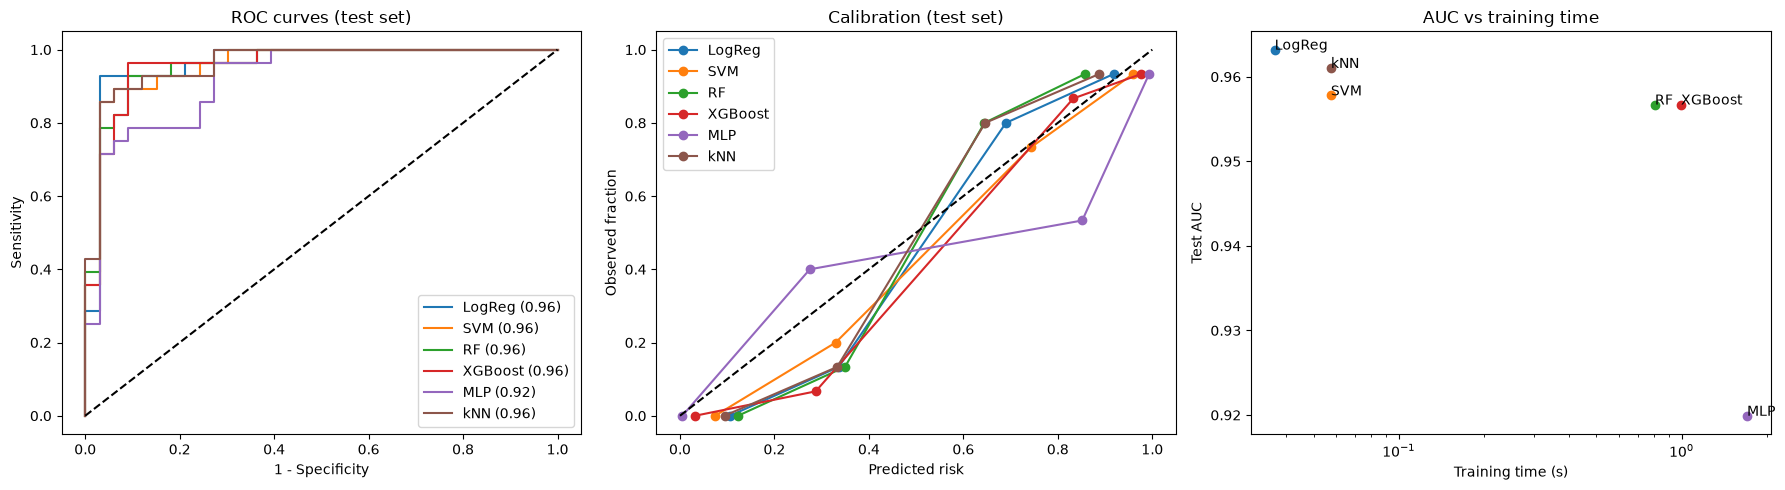

In [7]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for n, p in probs.items():
    fpr, tpr, _ = roc_curve(yt, p)
    ax[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(yt, p):.2f})")
    fr, mp = calibration_curve(yt, p, n_bins=4, strategy="quantile")
    ax[1].plot(mp, fr, marker="o", label=n)
    a = roc_auc_score(yt, p)
    ax[2].scatter(train_time[n], a); ax[2].annotate(n, (train_time[n], a))
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].legend()
ax[0].set(title="ROC curves (test set)", xlabel="1 - Specificity", ylabel="Sensitivity")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].legend()
ax[1].set(title="Calibration (test set)", xlabel="Predicted risk", ylabel="Observed fraction")
ax[2].set(xscale="log", title="AUC vs training time", xlabel="Training time (s)", ylabel="Test AUC")
plt.tight_layout(); plt.savefig("figures.png", dpi=300); plt.show()

In [8]:
%pip install scikit-posthocs statsmodels -q
import scikit_posthocs as sp
from scipy.stats import friedmanchisquare, norm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar

fs = pd.DataFrame(fold_scores)
print(friedmanchisquare(*[fs[c] for c in fs]))
nem = sp.posthoc_nemenyi_friedman(fs.values); nem.index = nem.columns = fs.columns
display(nem.round(3))

def _mid(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1); i = j
    T2 = np.empty(N); T2[J] = T + 1
    return T2

def delong(y, p1, p2):
    o = (-y).argsort(); y = y[o]; m = int(y.sum()); n = len(y) - m
    P = np.vstack([p1[o], p2[o]])
    tz = np.array([_mid(P[r]) for r in range(2)])
    tx = np.array([_mid(P[r, :m]) for r in range(2)])
    ty = np.array([_mid(P[r, m:]) for r in range(2)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / (2 * n)
    S = np.cov((tz[:, :m] - tx) / n) / m + np.cov(1 - (tz[:, m:] - ty) / m) / n
    l = np.array([1, -1])
    return 2 * norm.sf(abs((aucs[0] - aucs[1]) / np.sqrt(l @ S @ l)))

others = [n for n in probs if n != "LogReg"]
pd_, pm = [], []
for n in others:
    pd_.append(delong(yt, probs["LogReg"], probs[n]))
    a = (probs["LogReg"] >= thr["LogReg"]).astype(int) == yt
    b = (probs[n] >= thr[n]).astype(int) == yt
    pm.append(mcnemar([[(a & b).sum(), (a & ~b).sum()],
                       [(~a & b).sum(), (~a & ~b).sum()]], exact=True).pvalue)
tests = pd.DataFrame({"Model": others,
    "DeLong p": pd_, "DeLong p (Holm)": multipletests(pd_, method="holm")[1],
    "McNemar p": pm, "McNemar p (Holm)": multipletests(pm, method="holm")[1]}).round(4)
tests.to_csv("tests.csv", index=False); tests

Note: you may need to restart the kernel to use updated packages.
FriedmanchisquareResult(statistic=np.float64(12.771428571428572), pvalue=np.float64(0.025617524044084183))



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


,LogReg,SVM,RF,XGBoost,MLP,kNN
LogReg,1.000,0.985,1.000,0.538,0.028,0.913
SVM,0.985,1.000,0.996,0.913,0.168,0.999
RF,1.000,0.996,1.000,0.650,0.047,0.959
XGBoost,0.538,0.913,0.650,1.000,0.756,0.985
MLP,0.028,0.168,0.047,0.756,1.000,0.326
kNN,0.913,0.999,0.959,0.985,0.326,1.000


,Model,DeLong p,DeLong p (Holm),McNemar p,McNemar p (Holm)
0,SVM,0.4148,1.0000,1.0000,1.0
1,RF,0.4916,1.0000,1.0000,1.0
2,XGBoost,0.5695,1.0000,0.2500,1.0
3,MLP,0.0546,0.2728,0.5078,1.0
4,kNN,0.7661,1.0000,1.0000,1.0


C:\ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


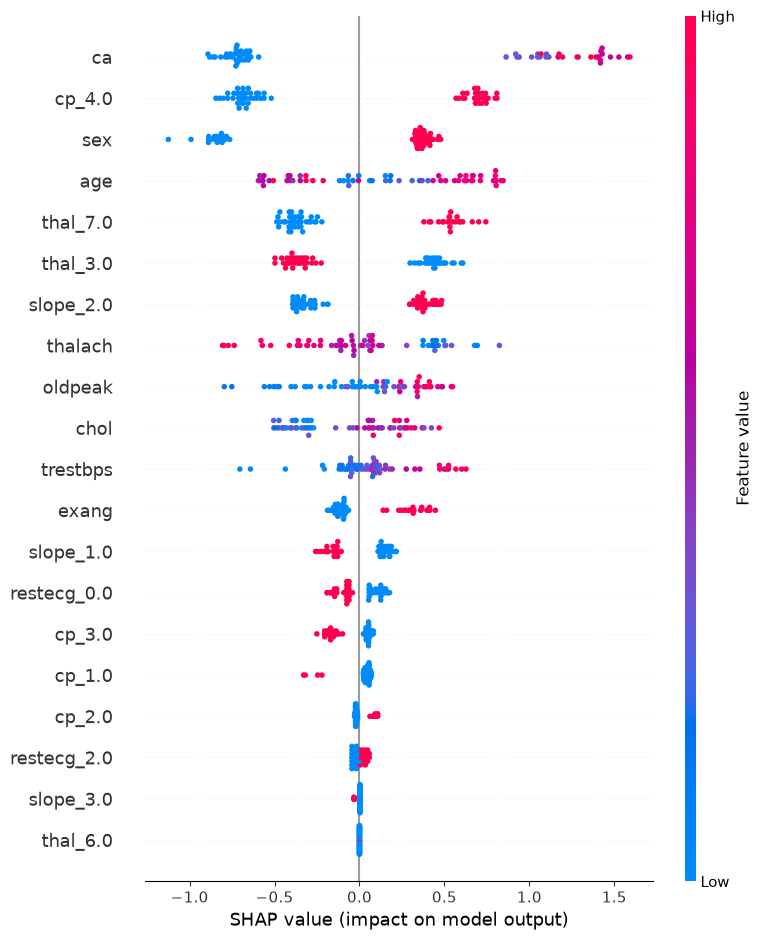

In [9]:
import shap
xgb = best_models["XGBoost"]
pre = xgb.named_steps["pre"]
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
Xt = pd.DataFrame(pre.transform(X_test), columns=names)
sv = shap.TreeExplainer(xgb.named_steps["clf"]).shap_values(Xt)
shap.summary_plot(sv, Xt, show=False)
plt.savefig("shap.png", dpi=300, bbox_inches="tight"); plt.show()

In [10]:
import sys, sklearn, xgboost, shap, scipy, numpy, pandas, scikit_posthocs, statsmodels
print("Python", sys.version.split()[0])
print("scikit-learn", sklearn.__version__)
print("xgboost", xgboost.__version__)
print("shap", shap.__version__)
print("scipy", scipy.__version__)
print("numpy", numpy.__version__)
print("pandas", pandas.__version__)
print("scikit-posthocs", scikit_posthocs.__version__)
print("statsmodels", statsmodels.__version__)


Python 3.13.14
scikit-learn 1.9.1
xgboost 3.4.1
shap 0.54.1
scipy 1.18.1
numpy 2.5.4
pandas 3.1.1
scikit-posthocs 0.17.1
statsmodels 0.15.0
